# Libaries and Preamble

In [15]:
import pandas as pd
import numpy as np
from functions import read_squid_file
from functions import determine_critical_temp
import matplotlib.pyplot as plt
import os
import statistics

In [16]:
#=======================================================================
# matplotlib rc — academic / journal style
#=======================================================================
plt.rcParams.update({
    "font.family":       "serif",
    "font.size":         10,
    "axes.labelsize":    10,
    "axes.titlesize":    10,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "lines.linewidth":   1.0,
    "axes.linewidth":    0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "xtick.major.size":  4.0,
    "ytick.major.size":  4.0,
    "xtick.minor.size":  2.0,
    "ytick.minor.size":  2.0,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.top":         True,
    "ytick.right":       True,
    "axes.grid":         True,
    "grid.color":        "#CCCCCC",
    "grid.linewidth":    0.4,
    "grid.linestyle":    "--",
    "grid.alpha":        0.6,
    "axes.axisbelow":    True,
    "figure.facecolor":  "white",
    "figure.figsize":    [7,4],
    "axes.facecolor":    "white",
    "savefig.dpi":       600,
    "savefig.bbox":      "tight",
    "savefig.facecolor": "white",
    "figure.dpi":        150,
    "legend.framealpha": 0.9,
    "legend.edgecolor":  "#AAAAAA",
    "legend.frameon":    True,
})

In [17]:
# pb = read_squid_file(
    # "/home/thomp/high-temperature-superconductivity/data/2026/10/2026-10-14 Pb MvsT FW Various Field_00001.dat",
# )
# pb.head()

In [18]:
# plt.plot(pb["Temperature (K)"],pb["DC Moment Fixed Ctr (emu)"])
# plt.title("2026-10-09-Pb-MvsT")
# plt.ylabel("DC Moment Fixed Ctr (emu)")
# plt.xlabel("Temperature (K)")

### Current Plan for Data Analysis 
- we need a method for looping throught a set number of files
- easiest way is to make a folder for the data 
- and then loop throught the folder and get all the raw data 


In [19]:
# Source - https://stackoverflow.com/a/10378012
# Posted by anselm, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-15, License - CC BY-SA 4.0
# edited by ben thomposn

from pathlib import Path
runs = {}
pathlist = Path(
    "data/2026/10/26-10-15 Pb Analysis Folder"
).glob("**/*.dat")
for path in sorted(pathlist):
    run_number = path.stem[-5:]
    runs[run_number] = read_squid_file(str(path))
for run_number, data in runs.items():
    print(f"Run {run_number}")

Run 00001
Run 00002
Run 00003
Run 00004
Run 00005


In [20]:
for run_number, dataframe in runs.items():
    print(f"Run {run_number}")
    print(dataframe.head())
    print("="*80)

Run 00001
   Time Stamp (sec)  Temperature (K)  Magnetic Field (Oe)  Moment (emu)  \
0      4.001173e+09         2.001248           149.626175           NaN   
1      4.001173e+09         2.005023           149.626175           NaN   
2      4.001173e+09         2.008357           149.626175           NaN   
3      4.001173e+09         2.018766           149.626175           NaN   
4      4.001173e+09         2.027640           149.626175           NaN   

   M. Std. Err. (emu)  Transport Action  Center Position (mm)  \
0                 NaN                 6             31.809032   
1                 NaN                 6             31.809032   
2                 NaN                 6             31.809032   
3                 NaN                 6             31.809032   
4                 NaN                 6             31.809032   

   AC Susceptibility (emu/Oe)  AC Suscept. Std Err. (emu/Oe)  AC X' (emu/Oe)  \
0                         NaN                            NaN        

In [21]:

# for run_number, dataframe in runs.items():
#     field = np.mean(dataframe["Magnetic Field (Oe)"])
#     plt.plot(
#         dataframe["Temperature (K)"],
#         dataframe["DC Moment Fixed Ctr (emu)"],
#         label=f"Average Applied Field: {field:.1f} Oe",
#     )

# plt.title("Pb MvsT")
# plt.xlabel("Temperature (K)")
# plt.ylabel("DC Moment Fixed Ctr (emu)")
# plt.legend()
# plt.show()

# Determining T_C for a singlular Datafram


In [22]:
# def determine_turning_points(dataframe: pd.DataFrame, threshold: float):
#     moment = dataframe["DC Moment Fixed Ctr (emu)"]
#      moment_norm =-1*(moment / np.min(moment))
#     temperature = dataframe["Temperature (K)"]
#     dm_dt = moment_norm/temperature
#     mask = dm_dt < threshold



In [23]:
# df = runs["00001"]
# df_tp = determine_turning_points(df, 0.001)
# print(df_tp)
# turning_point = df_tp.iloc[0]
# moment = df["DC Moment Fixed Ctr (emu)"]
# temperature = df["Temperature (K)"]

# m_norm =-1*(moment / np.min(moment))
# dm_dt = np.gradient(moment, temperature)
# d2m_dt2 = np.gradient(dm_dt, temperature)

# plt.plot(temperature, moment, label="Pb")
# # plt.plot(temperature, dm_dt, label="Pb 1st derivative")
# # plt.plot(temperature, d2m_dt2, label="Pb 2nd derivative")
# # plt.plot(temperature, m_norm/temperature, label="Normalised moment")

# plt.ylabel("DC Moment / derivative")
# plt.xlabel("Temperature (K)")
# plt.legend()
# plt.show()

# attempt 2 line intersection 
- we need to select the first proportion of the data

In [24]:
# def determine_critical_temp(dataframe: pd.DataFrame, lo: float = 0.2, hi: float = 0.8):
#     """
#         Function for determining Tc, it takes the steep part of the curve, in the middle 
    
#         kwargs:
#         dataframe: the dataframe that is inserted into the funciton, expcected to be from MPMS3
#         lo: the lower window, this can be tuned
#         hi: the upper window, this can be tuned 
#         """
#     df = dataframe.sort_values("Temperature (K)")
#     temperature = df["Temperature (K)"].to_numpy()
#     moment = df["DC Moment Fixed Ctr (emu)"].to_numpy()

#     m_sc = np.median(moment[:10])       
#     m_n = np.median(moment[-10:])       
#     moment_norm = (moment - m_n) / (m_sc - m_n)

#     mask = (moment_norm < hi) & (moment_norm > lo)
#     if mask.sum() < 3:
#         return np.nan, np.full_like(temperature, np.nan), np.zeros_like(temperature)

#     slope, intercept = np.polyfit(temperature[mask], moment_norm[mask], 1)
#     fitted_line = slope * temperature + intercept

#     t_crit = -intercept / slope if slope != 0 else np.nan
#     return t_crit, fitted_line, np.zeros_like(temperature)

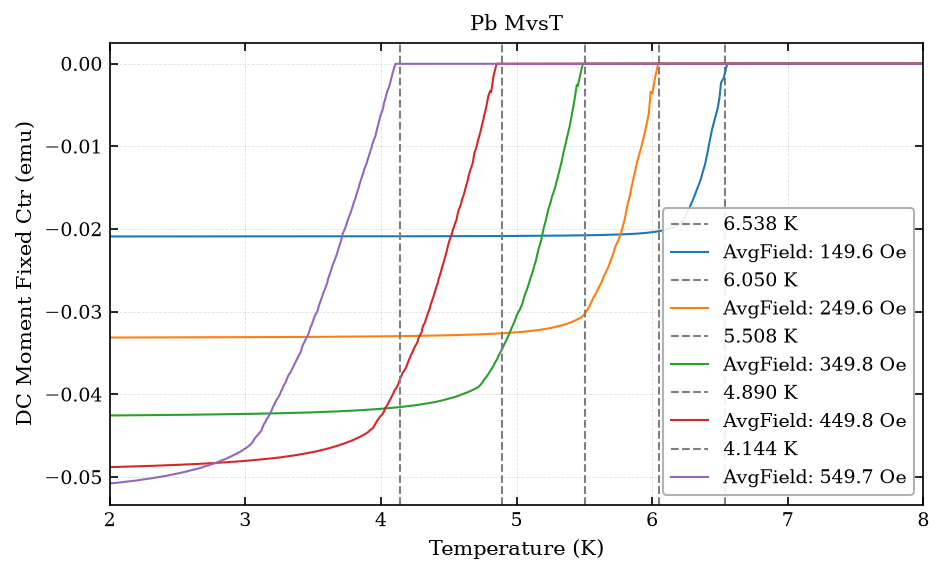

In [25]:

for run_number, dataframe in runs.items():
    field = np.mean(dataframe["Magnetic Field (Oe)"])
    crit_temp, fitted_line, _ = determine_critical_temp(dataframe)
    plt.axvline(crit_temp, color="tab:grey", linestyle="--", label=f"{crit_temp:.3f} K")
    plt.plot(
        dataframe["Temperature (K)"],
        dataframe["DC Moment Fixed Ctr (emu)"],
        label=f"AvgField: {field:.1f} Oe",
    )
    
plt.title("Pb MvsT")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.xlim(2,8)
plt.show()

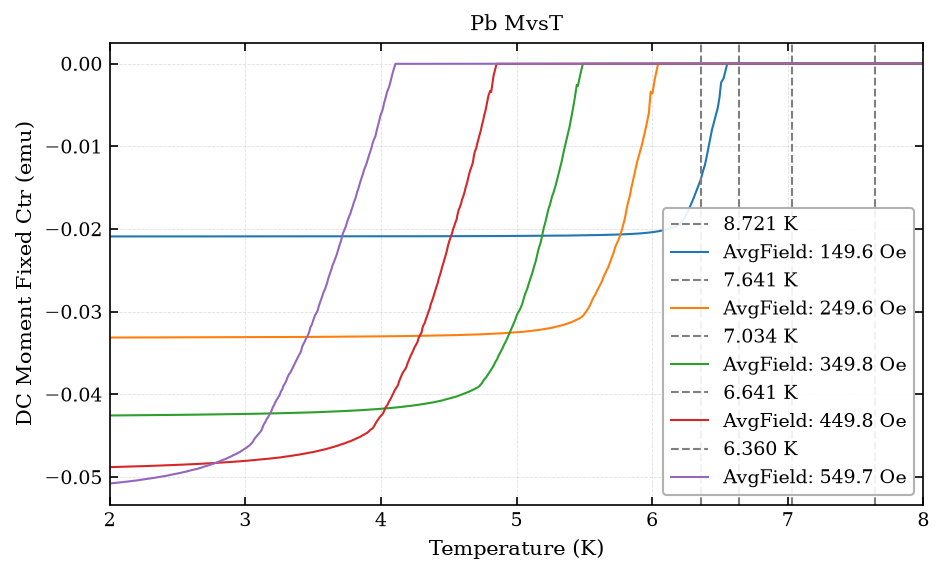

In [26]:
for run_number, dataframe in runs.items():
    field = np.mean(dataframe["Magnetic Field (Oe)"])
    crit_temp, fitted_line, _ = determine_critical_temp(dataframe,0,1)
    plt.axvline(crit_temp, color="tab:grey", linestyle="--", label=f"{crit_temp:.3f} K")
    plt.plot(
        dataframe["Temperature (K)"],
        dataframe["DC Moment Fixed Ctr (emu)"],
        label=f"AvgField: {field:.1f} Oe",
    )
    
plt.title("Pb MvsT")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.xlim(2,8)
plt.show()

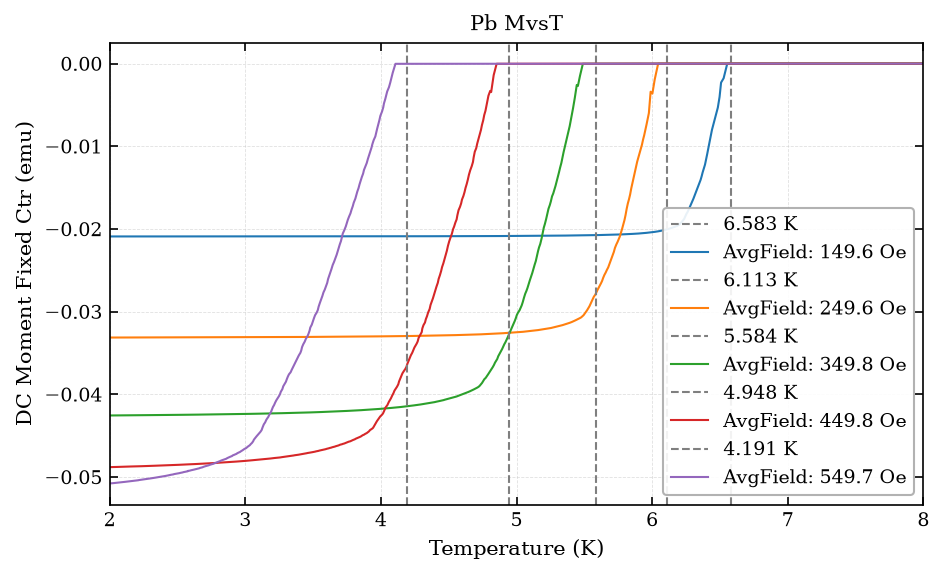

In [27]:
for run_number, dataframe in runs.items():
    field = np.mean(dataframe["Magnetic Field (Oe)"])
    crit_temp, fitted_line, _ = determine_critical_temp(dataframe,0.1,0.9)
    plt.axvline(crit_temp, color="tab:grey", linestyle="--", label=f"{crit_temp:.3f} K")
    plt.plot(
        dataframe["Temperature (K)"],
        dataframe["DC Moment Fixed Ctr (emu)"],
        label=f"AvgField: {field:.1f} Oe",
    )
    
plt.title("Pb MvsT")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.xlim(2,8)
plt.show()

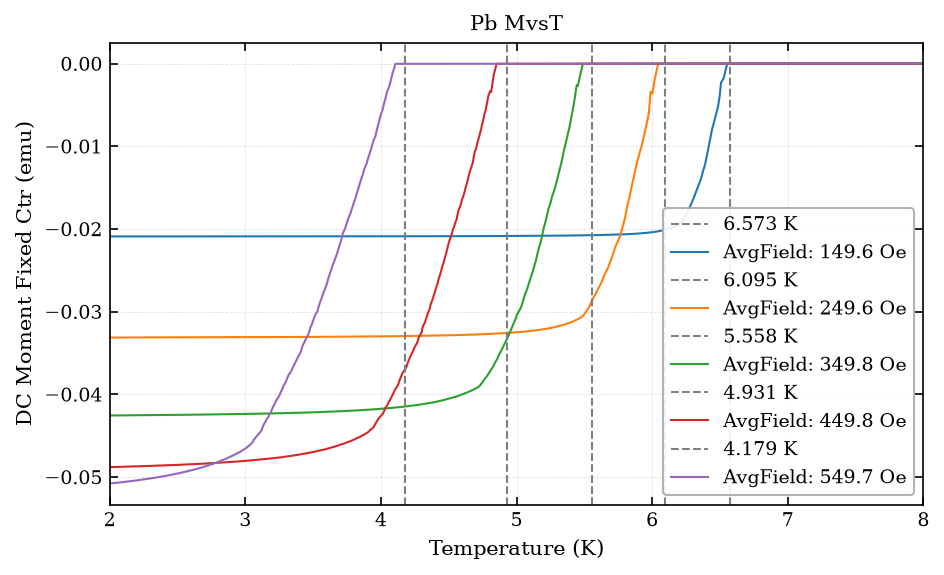

In [28]:
for run_number, dataframe in runs.items():
    field = np.mean(dataframe["Magnetic Field (Oe)"])
    crit_temp, fitted_line, _ = determine_critical_temp(dataframe,0.2,0.8)
    plt.axvline(crit_temp, color="tab:grey", linestyle="--", label=f"{crit_temp:.3f} K")
    plt.plot(
        dataframe["Temperature (K)"],
        dataframe["DC Moment Fixed Ctr (emu)"],
        label=f"AvgField: {field:.1f} Oe",
    )
    
plt.title("Pb MvsT")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.xlim(2,8)
plt.show()

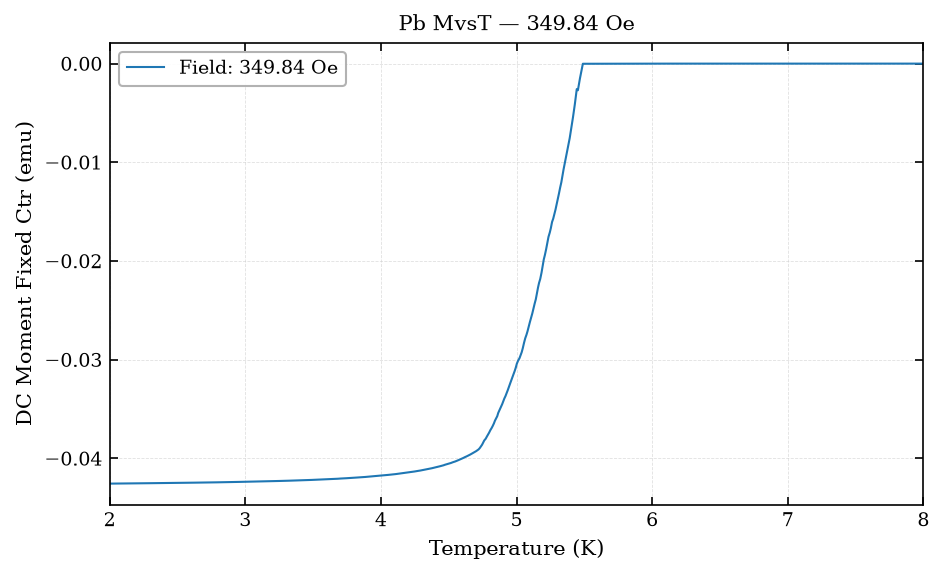

In [34]:
dataframe = read_squid_file(
    "data/2026/10/26-10-15 Pb Analysis Folder/2026-10-14 Pb MvsT FW Various Field_00003.dat",
)
field = np.mean(dataframe["Magnetic Field (Oe)"])
plt.plot(
    dataframe["Temperature (K)"],
    dataframe["DC Moment Fixed Ctr (emu)"],
    label=f"Field: {field:.2f} Oe",
)

plt.title(f"Pb MvsT — {field:.2f} Oe")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.xlim(2, 8)
plt.savefig("pb_mvst_350oe_fig5.svg", transparent=True, dpi=600)
plt.show()